# Calibration, decision thresholds, explanations, and final evaluation

The model is already frozen. This notebook reads saved reports and demonstrates inference without retraining. Calibration methods are compared on a group-preserving internal calibration holdout and the selected method is refitted on the full calibration partition. Threshold selection uses its own independent holdout.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
METRICS = ROOT / "reports" / "metrics"
FIGURES = ROOT / "reports" / "figures"
assert (METRICS / "final_test_metrics.json").exists(), "Run the full training CLI first."


def read_json(name):
    return json.loads((METRICS / name).read_text())


def show_figure(name):
    display(Image(filename=str(FIGURES / name)))

,method,brier_score,log_loss,roc_auc,average_precision,fit_size,validation_size
0,none,0.138224,0.436807,0.878525,0.420696,7493,7525
1,sigmoid,0.048513,0.173541,0.878525,0.420696,7493,7525
2,isotonic,0.048582,0.173943,0.877427,0.397333,7493,7525


Selected calibration: sigmoid


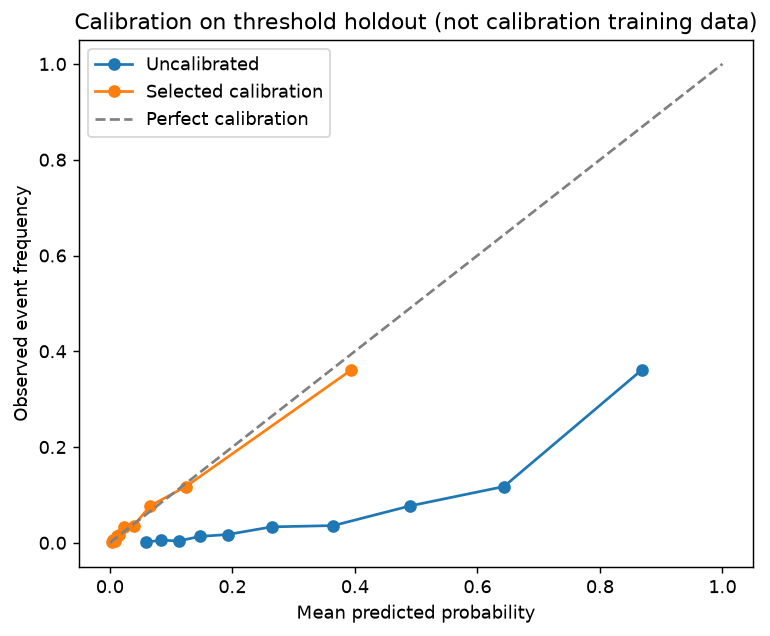

In [2]:
frozen = read_json("selection_frozen.json")
display(pd.read_csv(METRICS / "calibration_comparison.csv"))
print("Selected calibration:", frozen["calibration_method"])
show_figure("calibration_curve.png")

## Conditional cost and threshold sensitivity

C_FP:C_FN is always ordered false-positive cost first. The 1:5 default is a hypothetical research assumption. Exact candidate thresholds use `probability >= threshold`. Ties prefer the highest threshold, meaning fewer positive classifications. The all-negative boundary is one representable float above the largest probability.

,strategy,roc_auc,average_precision,precision,recall,f1,accuracy,balanced_accuracy,brier_score,log_loss,threshold,tn,fp,fn,tp,total_cost,cost_per_record,n_records,positive_rate
0,default_0.5,0.868681,0.402114,0.563536,0.204,0.299559,0.936468,0.596364,0.049254,0.177081,0.500000,6929,79,398,102,2069.0,0.275573,7508,0.066596
1,f1_optimized,0.868681,0.402114,0.351190,0.590,0.440299,0.900107,0.756116,0.049254,0.177081,0.165056,6463,545,205,295,1570.0,0.209110,7508,0.066596
2,cost_optimized,0.868681,0.402114,0.345622,0.600,0.438596,0.897709,0.759475,0.049254,0.177081,0.159317,6440,568,200,300,1568.0,0.208844,7508,0.066596


,cost_fp,cost_fn,roc_auc,average_precision,precision,recall,f1,accuracy,balanced_accuracy,brier_score,log_loss,threshold,tn,fp,fn,tp,total_cost,cost_per_record,n_records,positive_rate
0,1,1,0.868681,0.402114,0.660714,0.148,0.241830,0.938199,0.571289,0.049254,0.177081,0.581882,6970,38,426,74,464.0,0.061801,7508,0.066596
1,1,2,0.868681,0.402114,0.446316,0.424,0.434872,0.926612,0.693236,0.049254,0.177081,0.314638,6745,263,288,212,839.0,0.111747,7508,0.066596
2,1,5,0.868681,0.402114,0.345622,0.600,0.438596,0.897709,0.759475,0.049254,0.177081,0.159317,6440,568,200,300,1568.0,0.208844,7508,0.066596
3,1,10,0.868681,0.402114,0.221591,0.780,0.345133,0.802877,0.792255,0.049254,0.177081,0.071400,5638,1370,110,390,2470.0,0.328982,7508,0.066596
4,1,20,0.868681,0.402114,0.188406,0.832,0.307238,0.750133,0.788146,0.049254,0.177081,0.050983,5216,1792,84,416,3472.0,0.462440,7508,0.066596


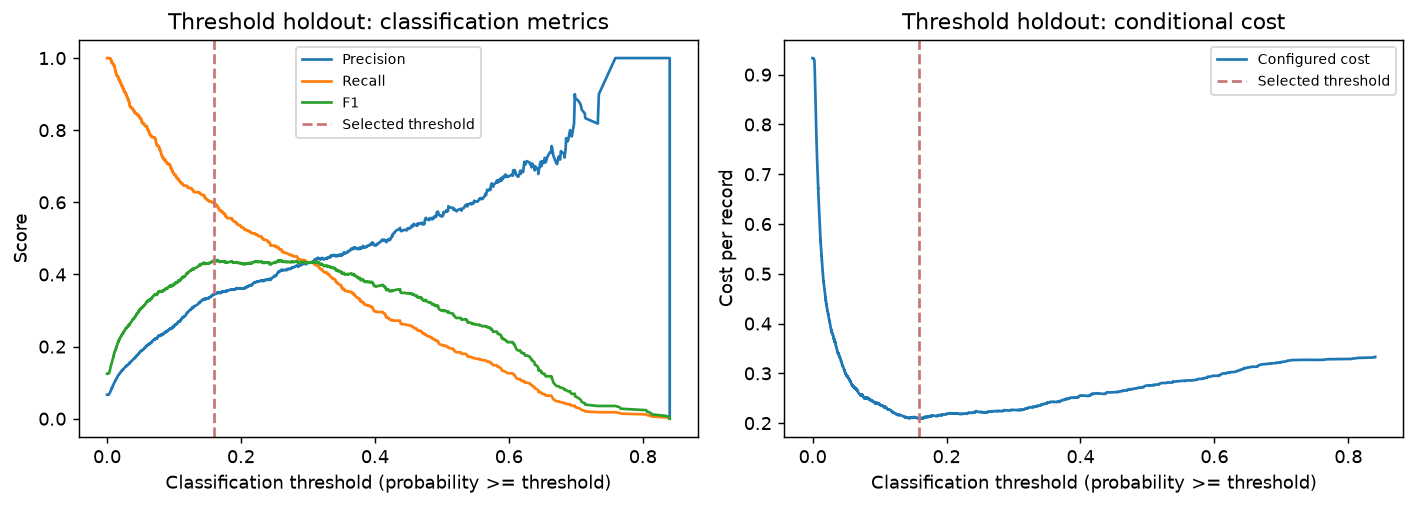

In [3]:
display(pd.read_csv(METRICS / "threshold_comparison.csv"))
display(pd.read_csv(METRICS / "cost_sensitivity.csv"))
show_figure("threshold_optimization.png")

## SHAP

SHAP explains the uncalibrated model output in the recorded units. Contributions are checked for additivity. A separate sigmoid calibrator does not make these contributions percentage-point changes in the displayed calibrated risk. Correlated source and engineered features can share attribution. Plots disclose no raw customer feature values.

partition                                                         selection
sample_size                                                             400
output_space                       uncalibrated log-odds (raw model margin)
explains_calibrated_probability                                       False
additivity_checked                                                     True
dtype: object

,feature,mean_absolute_shap
0,RevolvingUtilizationOfUnsecuredLines,0.401209
1,log_utilization,0.373381
2,weighted_past_due,0.323962
3,age,0.255169
4,total_past_due,0.239270
5,has_past_due,0.210642
6,NumberOfOpenCreditLinesAndLoans,0.115584
7,has_severe_delinquency,0.092545
8,real_estate_share,0.071823
9,DebtRatio,0.064926


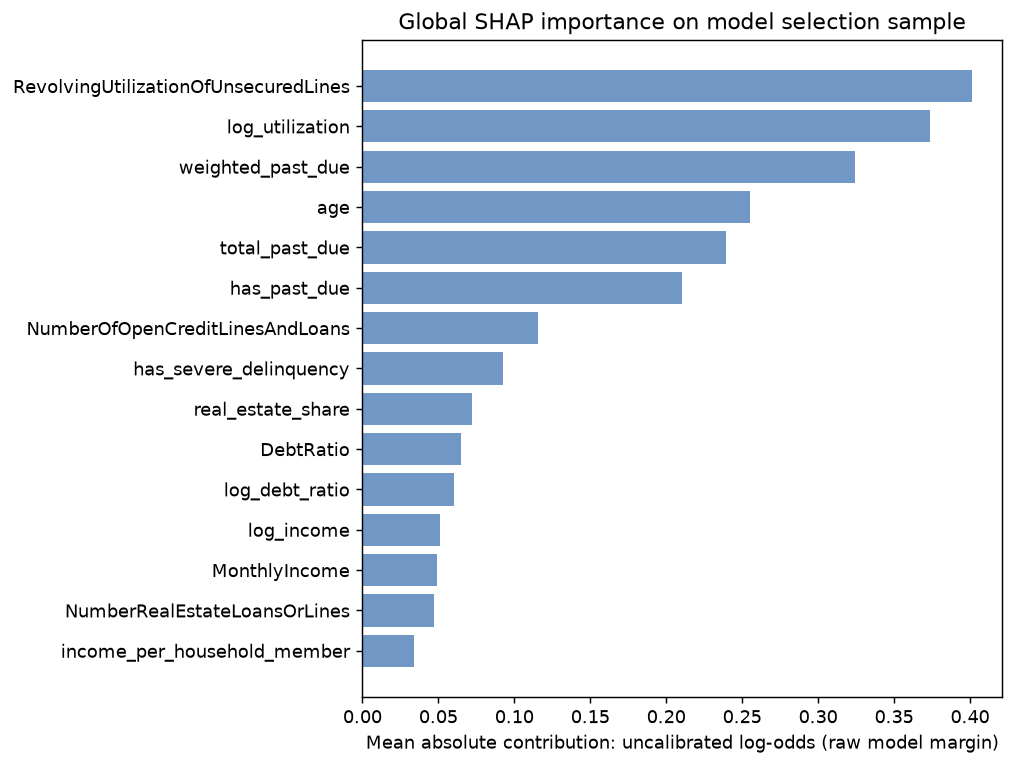

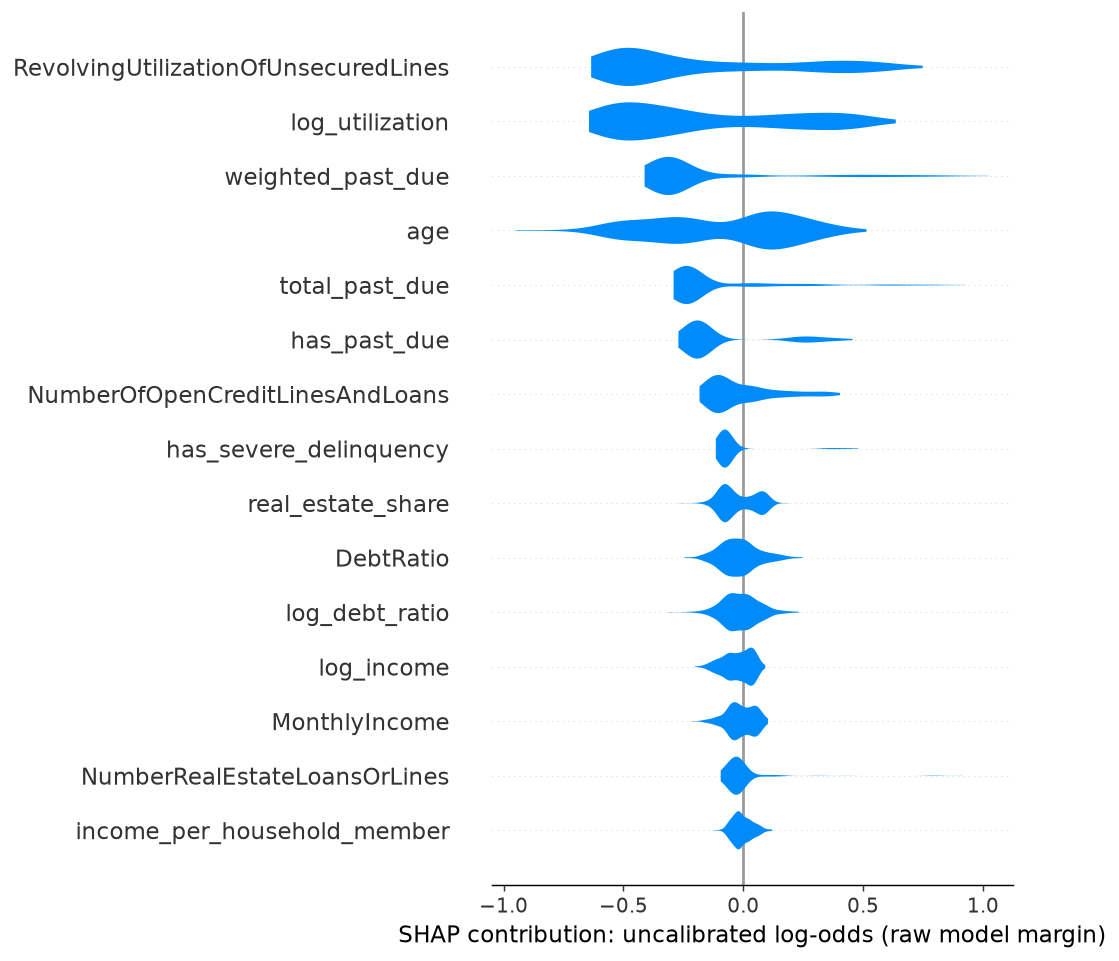

In [4]:
display(pd.Series(read_json("shap_metadata.json")))
display(pd.read_csv(METRICS / "shap_importance.csv").head(12))
show_figure("shap_importance.png")
show_figure("shap_summary.png")

## Independent final result

Model, preprocessing, calibration, and threshold were saved before these labels were evaluated. The 95% intervals use a stratified row bootstrap conditional on the fixed fitted model and split; they do not include model-selection uncertainty or fully address within-group dependence.

,Final test
roc_auc,0.868203
average_precision,0.402234
precision,0.353565
recall,0.599401
f1,0.444774
accuracy,0.900133
balanced_accuracy,0.760519
brier_score,0.048721
log_loss,0.176088
confusion_matrix,"[[12902, 1097], [401, 600]]"


,lower,upper
roc_auc,0.855129,0.878029
average_precision,0.373537,0.430174
brier_score,0.047490,0.050269


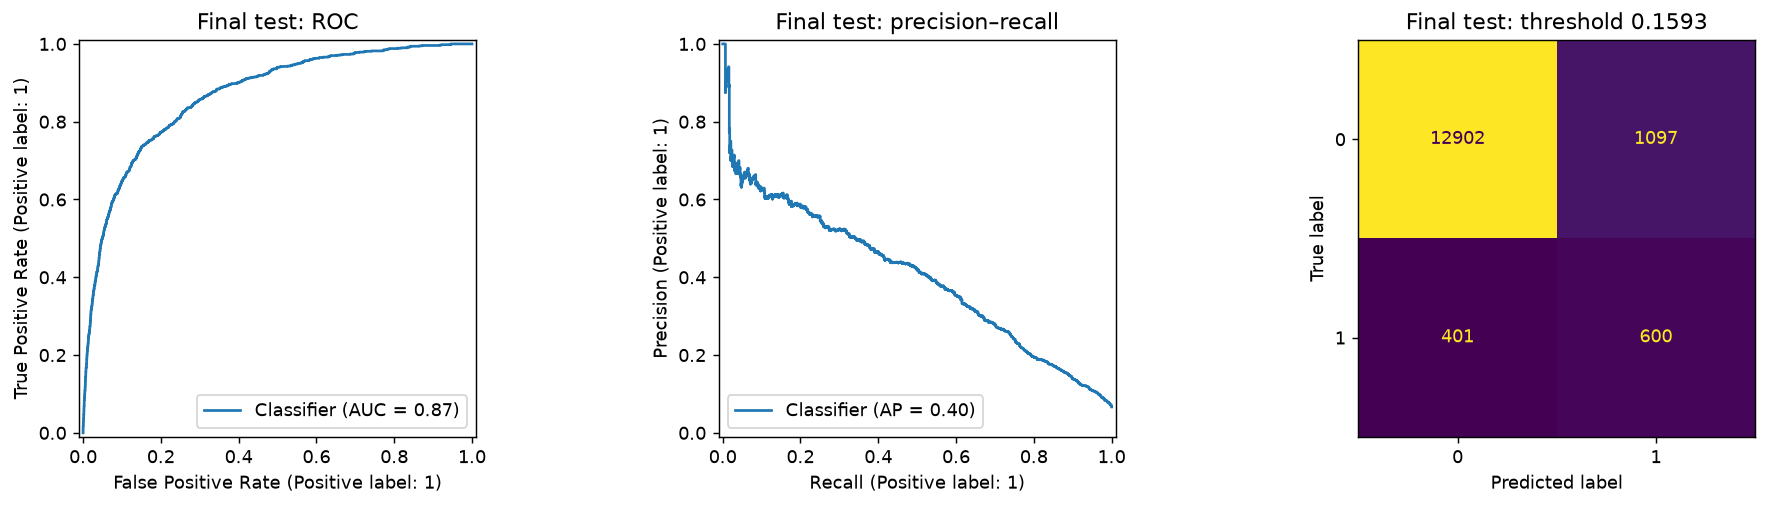

In [5]:
final = read_json("final_test_metrics.json")
display(
    pd.Series(
        {
            key: value
            for key, value in final.items()
            if key not in ["confidence_intervals_95", "artifact_sha256", "dataset_sha256"]
        }
    ).to_frame("Final test")
)
display(pd.DataFrame(final["confidence_intervals_95"]).T)
show_figure("final_evaluation.png")

## Errors, age, and subgroups

These are post-hoc diagnostics, not a basis for retuning the evaluated model. Groups with fewer than 50 records or fewer than five events/non-events do not receive group metrics. Age ablation uses only selection data and keeps estimator parameters fixed. Neither omitting age nor observing subgroup metrics constitutes a fairness audit.

In [6]:
display(pd.DataFrame(read_json("error_analysis.json")).T)
display(pd.read_csv(METRICS / "subgroup_metrics.csv"))
display(pd.read_csv(METRICS / "age_ablation.csv"))

,n_records,missing_income_rate,median_age,median_utilization,debt_ratio_above_10_rate
false_positive,1097.0,0.147675,46.0,0.901475,0.149499
false_negative,401.0,0.134663,47.0,0.431579,0.147132
within_0.02_of_threshold,334.0,0.116766,47.0,0.731325,0.125749
high_confidence_error,82.0,0.243902,52.5,0.060345,0.243902


,grouping,group,n_records,n_positive,interpretation,roc_auc,average_precision,precision,recall,f1,...,brier_score,log_loss,threshold,tn,fp,fn,tp,total_cost,cost_per_record,positive_rate
0,age,31-45,3992,378,Descriptive only; no fairness guarantee,0.845751,0.442566,0.364353,0.611111,0.456522,...,0.066872,0.233832,0.159317,3211,403,147,231,1138.0,0.285070,0.094689
1,age,46-60,5300,345,Descriptive only; no fairness guarantee,0.855588,0.372763,0.337134,0.600000,0.431700,...,0.049138,0.178653,0.159317,4548,407,138,207,1097.0,0.206981,0.065094
2,age,<=30,1087,133,Descriptive only; no fairness guarantee,0.844529,0.469660,0.393162,0.691729,0.501362,...,0.081773,0.277355,0.159317,812,142,41,92,347.0,0.319227,0.122355
3,age,>60,4621,145,Descriptive only; no fairness guarantee,0.875777,0.327704,0.325581,0.482759,0.388889,...,0.024789,0.099441,0.159317,4331,145,75,70,520.0,0.112530,0.031378
4,income,2500-6000,5213,437,Descriptive only; no fairness guarantee,0.872288,0.437049,0.367296,0.668192,0.474026,...,0.058895,0.204492,0.159317,4273,503,145,292,1228.0,0.235565,0.083829
5,income,<=2500,1780,158,Descriptive only; no fairness guarantee,0.842707,0.390933,0.341549,0.613924,0.438914,...,0.065375,0.228731,0.159317,1435,187,61,97,492.0,0.276404,0.088764
6,income,>6000,5103,256,Descriptive only; no fairness guarantee,0.844456,0.332523,0.319444,0.449219,0.373377,...,0.039551,0.151672,0.159317,4602,245,141,115,950.0,0.186165,0.050167
7,income,Missing,2904,150,Descriptive only; no fairness guarantee,0.893744,0.434450,0.372093,0.640000,0.470588,...,0.036364,0.135735,0.159317,2592,162,54,96,432.0,0.148760,0.051653
8,debt_ratio,0.3-1,5255,401,Descriptive only; no fairness guarantee,0.827244,0.373155,0.338279,0.568579,0.424186,...,0.057712,0.209370,0.159317,4408,446,173,228,1311.0,0.249477,0.076308
9,debt_ratio,1-10,590,66,Descriptive only; no fairness guarantee,0.848687,0.499393,0.359649,0.621212,0.455556,...,0.075372,0.257410,0.159317,451,73,25,41,198.0,0.335593,0.111864


,variant,roc_auc,average_precision,precision,recall,f1,accuracy,balanced_accuracy,brier_score,log_loss,threshold,tn,fp,fn,tp,total_cost,cost_per_record,n_records,positive_rate
0,with_age,0.860444,0.399490,0.214180,0.770709,0.335207,0.794969,0.783711,0.142299,0.447041,0.5,16723,4267,346,1163,5997.0,0.266545,22499,0.06707
1,without_age,0.858624,0.396561,0.212548,0.770046,0.333142,0.793235,0.782474,0.143607,0.451354,0.5,16685,4305,347,1162,6040.0,0.268456,22499,0.06707


## Saved-model inference on synthetic examples

These examples were created for demonstration and are not customer records. Threshold changes leave probability unchanged. The underlying dataset is historical, with no temporal or external validation and insufficient protected-attribute information for comprehensive fairness claims.

In [7]:
from creditguard.demo import DEMO_PROFILES
from creditguard.predict import load_predictor

predictor, _ = load_predictor(ROOT / "models/final")
examples = pd.DataFrame.from_dict(DEMO_PROFILES, orient="index")
display(predictor.predict(examples))

,risk_probability,classification_threshold,risk_class,model_name,calibrated
lower,0.006694,0.159317,below_threshold,catboost_engineered,True
intermediate,0.137311,0.159317,below_threshold,catboost_engineered,True
higher,0.710775,0.159317,above_threshold,catboost_engineered,True
